### Install new libraries

In [32]:
#%pip install ddgs trafilatura
#%pip install openai-agents


### Setup

In [33]:
import os
from dotenv import load_dotenv
import json
from pprint import pprint
from IPython.display import Image, display, Markdown
from ddgs import DDGS
import trafilatura

from agents import Agent, Runner, function_tool
from agents.extensions.handoff_prompt import RECOMMENDED_PROMPT_PREFIX


# ------------------------------
# Setup
# ------------------------------

load_dotenv()
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")
if OPENAI_API_KEY is None:
	raise Exception("API key is missing")

MODEL = "gpt-4.1-mini"


### Step 1: Define the Tools

In [34]:
@function_tool
def search_web(query: str):
	"""Search the web using DuckDuckGo browser. Returns 3 results."""
	ddgs = DDGS()
	results = ddgs.text(query, max_results=3)
	print(f"  \u2705 search_web: Got results for {query}")
	return json.dumps(results, indent=2)

In [35]:
@function_tool
def fetch_url(url: str):
	"""Fetch the content of a URL using trafilatura."""
	downloaded = trafilatura.fetch_url(url)
	if downloaded:
		text =  trafilatura.extract(downloaded)
		if text:
			truncated_text = text[:2000]  # Truncate to 2,000 characters
			print(f"  \u2705 fetch_url: Got text: {len(text)} chars from {url[:60]}")
			return truncated_text
	print(f"  \u274C Failed to fetch or extract text.") # For debugging
	return f"Could not extract text from {url}. Try a different source." # For LLM input feedback


### Step 2: Describe as LLM tools

In [36]:
tools = []

In [37]:
import base64
import urllib.request
from openai import OpenAI

openai_client = OpenAI()

@function_tool
def generate_image(prompt: str) -> str:
	"""Generate an image using gpt-image-1-mini and save it to a local file."""
	print(f"  🎨 generate_image prompt: {prompt[:80]}...")
	try:
		response = openai_client.images.generate(
			model="gpt-image-1-mini",
			prompt=prompt,
			size="1024x1024",
			quality="high",
			n=1
		)

		item = response.data[0]
		filename = "hero_image.png"

		# 1. Handle b64_json (Decode bytes and save locally)
		if getattr(item, "b64_json", None) and item.b64_json:
			with open(filename, "wb") as f:
				f.write(base64.b64decode(item.b64_json))
			print(f"  ✅ generate_image: Saved to {filename}")
			return f"Image generated successfully and saved locally as: {filename}"

		# 2. Handle HTTP URL (Download and save locally)
		if getattr(item, "url", None) and item.url:
			urllib.request.urlretrieve(item.url, filename)
			print(f"  ✅ generate_image: Saved to {filename}")
			return f"Image generated successfully and saved locally as: {filename}"

		return "Failed to generate image: API returned empty data."

	except Exception as e:
		print(f"  ❌ generate_image failed: {e}")
		return f"Failed to generate image: {e}"

### Step 2: The Agents

 This Agent Prompts tells the LLM who it is and how to behave. The key things:
- What its job is
- What tools it has
- What process to follow
- What output format to produce




#### Research Agent

In [38]:

RESEARCH_AGENT_PROMPT = """You are a research specialist. Your job is to research a given topic
and produce a comprehensive research brief.

You have access to two tools:
- search_web: Search the web for information
- fetch_url: Fetch and read the full content of a web page

***IMPORTANT:
After each search with search_web, you MUST first explain your reasoning:
- Which URLs look most relevant and why
- Which ones you will fetch and why
- Which ones you are skipping and why
Only AFTER writing out your reasoning should you call fetch_url.
***

Your typical process:
1. Search for the topic to find relevant sources
2. Reflect on the search results — which sources look most relevant and why?
3. Fetch the full content of the 2-3 best URLs
4. Reflect on what you have gathered. Do you have enough? Are there gaps?
5. If there are gaps, search again with a different query
6. When you have enough information from at least 3 different sources, synthesize into a research brief

You MUST gather information from at least 3 distinct sources before delivering your brief.
If you have fewer than 3 sources, keep searching.

Your research brief MUST include:
- Key facts and statistics
- Main themes and arguments from the sources
- Notable data points
- Source URLs for attribution

Until you are ready, just keep working — search, fetch, think, reflect.
Do not rush. Take time to reflect between tool calls before deciding your next step.
Not every response needs a tool call — sometimes just thinking through what you have is the right move."""

research_agent = Agent(
	name="Research Agent",
	instructions=RESEARCH_AGENT_PROMPT,
	model=MODEL,
	tools=[search_web, fetch_url]
)


#### Image Generator Agent

In [39]:
IMAGE_AGENT_PROMPT = """You are an image prompt specialist. Given a topic and content summary, craft a single detailed gpt-image-1-mini prompt for a hero image.

Call generate_image exactly ONCE with your prompt. One image only.

IMPORTANT: Return ONLY the exact filename returned by generate_image in markdown format, like: ![hero image](hero_image.png). Do NOT add prefixes like 'sandbox:/'.

Behavior and style rules:
- Infer an appropriate visual **style** from the topic/brief. Supported styles: abstract, futuristic, photorealistic, illustrative, cartoon. Default: abstract/futuristic.
- If the brief explicitly requests 'cartoon', 'illustration', or references characters/people, you may produce a cartoon or illustrative image containing people/characters.
- Avoid creating images of real, identifiable private individuals or celebrities. Use generic, stylized characters or request permission for real-person likenesses.
- No text, logos, or words in the image.
- Focus on strong lighting, composition, single-concept clarity, and mood that matches the article tone.
- If people appear, keep poses natural and non-sexualized; ensure diverse and respectful representation.
- Prefer a single, compelling visual concept; avoid clutter. Mention camera angle or focal length only when relevant (e.g., close-up, wide shot).
- Keep prompts concise and under 200 words. Avoid anything that would trigger image safety filters.

Required output:
- Generate a single prompt string suitable for `gpt-image-1-mini` that follows the above rules. Then call `generate_image(prompt)` once.
- After the image is saved, return the exact filename (hero_image.png) in markdown format: ![hero image](hero_image.png)

IMPORTANT: When returning the image URL or filename, copy it EXACTLY character by character. Do not modify, shorten, or paraphrase the URL.
"""

image_agent = Agent(
	name="Image Agent",
	instructions=IMAGE_AGENT_PROMPT,
	model=MODEL,
	tools=[generate_image],
)

image_agent_as_tool = image_agent.as_tool(
	tool_name="image_agent",
	tool_description="Generate a hero image for an article based on a topic and content summary. Supply the topic and content summary.",
)


In [40]:
# Writer agents A & B: lightweight wrappers and an improved selector tool
# These are non-destructive wrappers. If you already have full writer agents, import them instead.
WRITER_A_PROMPT = """You are Writer A: The Journalist. Produce accurate, clear, and objective reporting-style articles. Start with a concise headline and lead paragraph summarizing the key facts. Provide sourced background, relevant context, and balanced reporting with quoted statements or attributions where appropriate. Return well-structured Markdown with headings: Headline, Lead, Background, Reporting, Sources, Conclusion. Prioritize factual accuracy, neutral tone, and clear citations or source URLs when available."""
WRITER_B_PROMPT = """You are Writer B: The Humorist. Produce entertaining, witty, and light-hearted articles that use satire, playful analogies, and clever observations to engage readers while remaining respectful and non-offensive.

Style and constraints:
- Use humor, irony, and light satire to explain ideas, but avoid targeting protected classes, private individuals, or creating hateful/offensive content.
- Keep tone playful and clever rather than cruel; prioritize clarity and readability.
- When appropriate, include amusing metaphors, pop-culture references, or brief humorous asides, but keep them concise and relevant.
- Maintain a logical structure: Executive Summary, Main Points (with headings), Humorous Examples or Analogies, and a Brief Conclusion.
- Prefer short paragraphs, occasional bullet lists, and inline code blocks only if illustrating a simple concept humorously.

Return Markdown suitable for publication with headings and an executive summary. """

# Minimal Agent wrappers (no specialized tools required here)
writer_a_agent = Agent(name="Writer A", instructions=WRITER_A_PROMPT, model=MODEL, tools=[])
writer_b_agent = Agent(name="Writer B", instructions=WRITER_B_PROMPT, model=MODEL, tools=[])

# Expose as tools the orchestrator can call
writer_a_tool = writer_a_agent.as_tool(tool_name="writer_a", tool_description="Technical writer: use for tutorials, code, implementation deep dives")
writer_b_tool = writer_b_agent.as_tool(tool_name="writer_b", tool_description="High-level writer: use for marketing, summaries, narratives")

# A more robust selector function the orchestrator can call to decide which writer to use
@function_tool
def choose_writer(topic: str, brief: str) -> str:
    """Return 'writer_a' or 'writer_b' using a simple scoring heuristic.

    Scoring:
    - Add +2 for technical tokens (code, tutorial, implement, API, SDK, integration, architecture, benchmark)
    - Add +1 for medium-technical tokens (study, research, dataset, evaluation)
    - Subtract 1 for marketing tokens (benefit, audience, promote, press, narrative, story, customer)
    - If final score >= 2 choose writer_a (technical), else writer_b (marketing/narrative)
    """
    t = ((topic or "") + " " + (brief or "")).lower()
    tech_tokens = ["implement", "tutorial", "code", "api", "sdk", "integration", "architecture", "benchmark", "performance", "latency", "throughput", "deploy", "ops", "infrastructure", "model training", "fine-tune"]
    mid_tokens = ["study", "research", "dataset", "evaluation", "analysis"]
    marketing_tokens = ["benefit", "audience", "promote", "press", "announcement", "story", "narrative", "customer", "case study", "marketing"]

    score = 0
    for k in tech_tokens:
        if k in t:
            score += 2
    for k in mid_tokens:
        if k in t:
            score += 1
    for k in marketing_tokens:
        if k in t:
            score -= 1

    # Heuristic: very short or clearly fictional topics lean marketing/narrative/humor
    if len(topic.split()) <= 3 and any(n in topic.lower() for n in ["fred", "flinstone", "batman", "superman", "cartoon"]):
        return "writer_b"

    return "writer_a" if score >= 2 else "writer_b"


### Orchestrator Agent

In [41]:
ORCHESTRATOR_AGENT_PROMPT = """You are the orchestrator of a multi-agent article writing system.
Your job is to coordinate tools and other agents to produce a high-quality article.
Use the tools available to you and/or delegate tasks to the appropriate agents.
Never do the work yourself. Always use tools or agents.
Your tools and agents are specialists and should be doing the work, you are the manager.

Deliver the selected research brief as the final output, and
include the image at the top of your final output in markdown format strictly as: ![hero image](hero_image.png)

CRITICAL: Do not add any path prefixes like 'sandbox:/' or folder names. Use 'hero_image.png' as the exact relative filename.

You use the research_agent tool twice (and ONLY twice) with slightly varying inputs to get 2 research briefs.
You pick the best research brief out of the two and deliver it as output.
Do not combine the two briefs, just pick the best one.
Do not do the research yourself or add anything, you MUST use the research_agent tool to get the briefs.

Once you have selected the best brief, you MUST use the image_agent tool to generate an image.
Use the research brief to supply the image agent with the topic and content summary it needs to generate the image.

Selection rules:
- Use the `choose_writer` tool to decide which writer to use for producing the article. The tool returns exactly the string 'writer_a' or 'writer_b'.
- After receiving the selector output, call the corresponding writer tool (`writer_a` or `writer_b`) exactly once with the topic and the chosen research brief to produce the article.
- If the chosen writer returns empty output or misses required sections, call the other writer as a fallback and return the better output.

Deliver the selected research brief as the final output, and
include the image URL at the top of your final output in markdown format like this: ![hero image](image_url)

IMPORTANT: When returning the image URL, copy it EXACTLY character by character. Do not modify, shorten, or paraphrase the URL.
"""

orchestrator_agent = Agent(
	name="Orchestrator Agent",
	model="o4-mini", ##Reasoning
	instructions=ORCHESTRATOR_AGENT_PROMPT,
	tools=[research_agent.as_tool(tool_name="research_agent", tool_description="Research a topic and return a brief with key facts, statistics, themes,  and source URLs. Pass the topic as input.", max_turns=25),
		image_agent_as_tool,
		writer_a_tool,
		writer_b_tool,
		choose_writer],
)


#### Writer Agent A: The Journalist

In [42]:
JOURNALIST_WRITER_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are an investigative journalist.
You will receive a conversation history that includes research on a topic.

Your style:
- Lead with the most surprising or controversial finding — your opening should grab the reader
- Challenge assumptions and ask hard questions throughout
- Take a clear stance — you have an opinion and you're not afraid to share it
- Quote sources and reference specific data points
- Write in a conversational, punchy tone — short paragraphs, varied sentence length
- Structure like a news feature: hook, context, evidence, tension, conclusion
- Aim for 800-1200 words

Do NOT use generic section headers like "Introduction", "Conclusion", or "Overview". Use creative, specific headers that grab attention.
Do NOT overuse headers. Only use one title and BETWEEN 2 and 3 headers in total for the entire article.
Do NOT use bullet points or numbered lists. Write in full sentences and paragraphs.
Do NOT ask for feedback, offer revisions, or include any commentary after the article.
Just deliver the finished article in markdown format. """

journalist_agent = Agent(
	name="Journalist Agent",
	instructions=JOURNALIST_WRITER_PROMPT,
	model=MODEL
)

#### Writer Agent B: The Humorist

In [43]:
HUMORIST_WRITER_PROMPT = RECOMMENDED_PROMPT_PREFIX + """You are a humorist writer.
You treat the topic like standup material, using absurd comparisons, dry wit, and sharp observational humor so the reader laughs while accidentally learning something.

Your style:
- Lead with an absurd comparison, a sharp punchline, or a ridiculously relatable observation that immediately hooks the reader
- Use dry wit, exaggeration, and unexpected metaphors to explain complex ideas
- Take a humorous stance — mock the absurdities of the topic while keeping the core facts accurate
- Weave real facts, data, or source quotes directly into setup-and-punchline structures
- Write in a conversational, punchy tone — comedic pacing, short paragraphs, and varied sentence length
- Structure like a humorous essay or standup bit with narrative flow: hook, context, evidence, hilarious tension, and a memorable landing
- Aim for 800-1200 words

Do NOT use generic section headers like "Introduction", "Conclusion", or "Overview". Use creative, specific, or witty headers that grab attention.
Do NOT overuse headers. Only use one title and BETWEEN 2 and 3 headers in total for the entire article.
Do NOT use bullet points or numbered lists. Write in full sentences and paragraphs.
Do NOT ask for feedback, offer revisions, or include any commentary after the article.
Just deliver the finished article in markdown format."""

humorist_agent = Agent(
	name="Humorist Agent",
	instructions=HUMORIST_WRITER_PROMPT,
	model=MODEL
)

#### Update the Orchestrator Agent for Humorist_agent

In [44]:
from agents import handoff

orchestrator_agent.handoffs = [humorist_agent]

#### Update the Orchestrator Agent

In [45]:
from agents import handoff

orchestrator_agent.handoffs = [journalist_agent]

In [46]:
from agents import trace

with trace("Journalist test", group_id="Learning AI Engineering"):
    result = await Runner.run(
        journalist_agent,
        input="Write an article about the following topic: Zebra migration patterns in Africa",
        max_turns=30
	)

In [47]:
from agents import trace

with trace("Humorist test", group_id="Learning AI Engineering"):
    result = await Runner.run(
        humorist_agent,
        input="Write an article about the following topic: Zebra migration patterns in Africa",
        max_turns=30
	)

#### Test Running the Journalist Agent

In [48]:
print(f"Agent: {getattr(result.last_agent, 'name', 'N/A')}")
print(f"----")
display(Markdown(result.final_output))

Agent: Humorist Agent
----


# When Stripes Hit the Road: The Surprisingly Social Lives of Migrating Zebras

If you think a road trip with friends means cramped cars, bad snacks, and endless debates over the aux cord, you haven’t seen zebra migration in Africa. These striped equine entrepreneurs have turned the dusty plains into their very own safari version of *The Amazing Race* — except instead of yelling "Are we there yet?" they’re just hoofing it, looking stylish, and dodging predators like nature’s black-and-white ninjas.

## Stripes, Stamina, and Safari Survival

Zebra migration patterns are the African plains’ best-kept secret. If wildebeests are the popular high school jocks who herd together in massive groups, zebras are the artsy, fashion-forward friends who know how to party in smaller, tight-knit crews — but when it’s time to move, they all come together for the ultimate stripy exodus. Zebras migrate primarily to follow freshly grown grasses after the rains, because apparently, zebra taste buds dismiss anything less than the crunchy green stuff like it’s last season’s socks.

These travels aren’t just a casual stroll. They can cover up to 500 miles in search of food and water — which considering their hooves aren’t really made for jogging marathons, is impressive. It's like someone told a track shoe-wearing, caffeine-fueled office worker to suddenly run a half marathon carrying a briefcase. Yet zebras do it with grace and coordination, their black-and-white stripes creating an optical illusion that confuses hungry lions and hyenas. Think of it as Mother Nature’s way of giving them hip camouflage — a sort of high-contrast Vogue cover shoot that doubles as a predator distraction tactic.

Migration timing is everything in the zebra world. They don’t just wander willy-nilly hoping to bump into the next lush field. Like seasoned travelers subscribing to a very exclusive safari newsletter, they follow rainfall patterns, moving with the rains to exploit the freshest buffet possible. This rain-following instinct links zebra journeys closely with other migratory species, most famously the wildebeests. Together, they form one of Earth’s greatest wildlife concerts, blending hoofbeats and roars over the Serengeti and Masai Mara plains.

## Social Stripes: Zebras Are Not Lone Rangers

Contrary to the solitary cowboy image, zebras have surprisingly intricate social lives. A typical zebra migration involves small family groups called harems, usually led by one stallion and a handful of mares with their foals. Picture a strict, yet oddly charming, club president making sure everyone has their sunscreen and snacks packed. They stick together, making the long haul not only safer but also more sociable, because who else is going to share the hilarious stories of dodging lions today?

When the herd assembles for migration, these groups come together to form massive, bustling caravans that can number up to thousands strong. It’s the ultimate block party, except the music is silent except for the thunderous choruses of hooves and occasional likes of grunts and snorts. And you thought your family reunions were noisy.

One interesting quirk: the stripes themselves might help zebras recognize each other, like natural QR codes. Every zebra’s stripe pattern is unique, as distinctive as a fingerprint or a particularly embarrassing yearbook photo. This individuality matters during migration, because heading into the vast wilderness without confusing who’s who could be a fatal social faux pas. Imagine if you accidentally followed the wrong zebra to the watering hole and ended up in a hyena meetup instead. Spoiler alert: not fun.

The relationships also help during rest stops. Zebras take turns standing guard, because someone’s got to keep an eye out for sneaky predators. This shared vigilance is like a group text constantly scanning for danger; only instead of reading Instagram updates, they’re scanning for lions. When the migration hits dangerous patches — river crossings, for example — zebras combine courage, persistence, and lots of wearing-on-the-edge striped bravery. Crocodiles lurking beneath might call it a buffet, but zebras call it a Friday night challenge.

## The Grand Finale: Why Migration Matters Beyond the Stripes

Migration isn’t just about zebras getting their fill of the green stuff. This seasonal exodus plays a massive role in the ecosystem, helping distribute nutrients and supporting the health of the African savannah. Zebras are like roaming lawnmowers with a penchant for balanced, eco-friendly landscaping. As they graze, they help control grass growth, benefiting hundreds of other species — from insects to elephants — that rely on the plains.

Scientists also view these migrations as critical signals of environmental health. Changes in zebra movement patterns can indicate shifts in climate, water availability, or human impact — essentially, zebras are the continent’s striped canaries in the coal mine, except these canaries are way cooler and also way faster.

As climate change and human development increasingly threaten these migration routes, conservationists are sounding alarms louder than a zebra stampede. Protecting migration corridors ensures the survival of these magnificent creatures and keeps the entire African ecosystem in balance. Otherwise, we might someday lose not only the breathtaking spectacle of thousands of zebras moving in synchronous style but also the delicate ecological dance that underpins the wild.

If zebras have taught us anything, it’s that sometimes you’ve got to follow the rains, stick with your friends, and keep your stripes sharp — because life, much like migration, is about moving forward together, one wild step at a time. And if you can do it looking fabulously black and white, well, that’s just icing on the savannah cake.

### Let's Run IT!

In [49]:
from agents import trace

with trace("Article Writer with Handoff", group_id="Learning AI Engineering"):
	result = await Runner.run(
		orchestrator_agent,
		input="Research the following topic and produce a comprehensive research brief: How will AI is used in healthcare 2040?",
		#input="Research the following topic and produce a comprehensive research brief: How seniors can understand AI",
		#input="Research the following topic and produce a comprehensive research brief: How to become an AI engineer",
		#input="Research the following topic and produce a comprehensive research brief: How to start a side gig as an AI engineer",
		max_turns=30
	)

  ✅ search_web: Got results for AI in healthcare future predictions 2040
  ✅ fetch_url: Got text: 11564 chars from https://matter.health/posts/healthcare-2040-how-ai-will-tran
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for future of AI in healthcare 2040 predictions report
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for future of AI in healthcare 2040 research articles
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for AI healthcare future trends 2040
  ✅ search_web: Got results for Allianz Partners healthcare 2040 report AI
  ❌ Failed to fetch or extract text.
  ❌ Failed to fetch or extract text.
  🎨 generate_image prompt: A futuristic, photorealistic scene illustrating artificial intelligence in healt...
  ✅ generate_image: Saved to hero_image.png


Agent: Orchestrator Agent
---



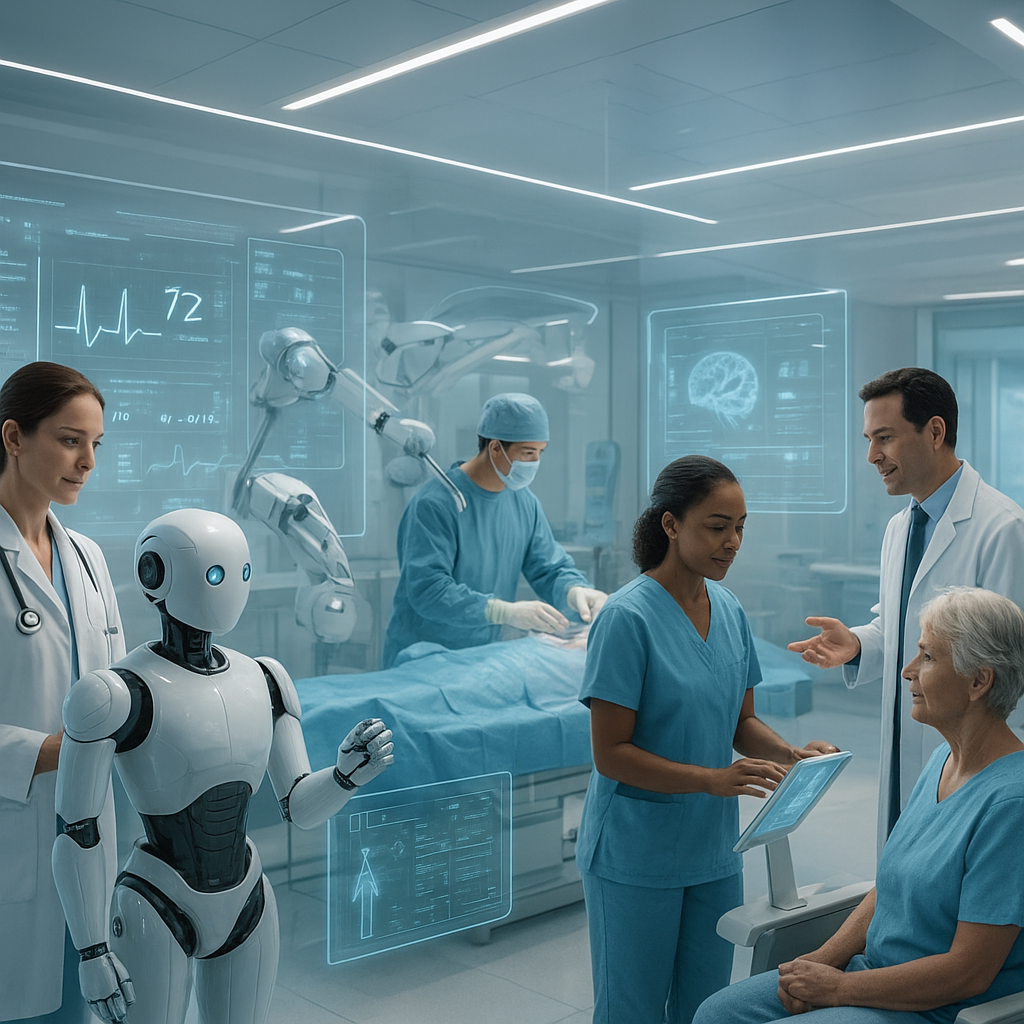



It seems there is a technical issue with the search tool at the moment. I will try to gather the information based on my existing knowledge and then when the tool is operational, I will verify and augment the information with recent data and forecasts regarding the future applications of AI in healthcare by 2040.

In [50]:
import base64
from IPython.display import Markdown, display, HTML

print(f"Agent: {getattr(result.last_agent, 'name', 'N/A')}")
print("---")

# Read local image bytes and encode to base64 data URI (bypasses browser caching)
with open("hero_image.png", "rb") as f:
	img_b64 = base64.b64encode(f.read()).decode("utf-8")
img_html = f'<img src="data:image/png;base64,{img_b64}" alt="Hero Image"/>'

# Build cleaned markdown without the markdown image reference
clean_output = result.final_output.replace("sandbox:/", "")
clean_output_no_image = clean_output.replace("![hero image](hero_image.png)", "")

# Display the embedded image (HTML) and then the markdown content
display(HTML(img_html))
display(Markdown(clean_output_no_image))

In [51]:
# from IPython.display import Image, display
# import time

# print(f"Agent: {result.last_agent.name}")
# print(f"---")


# ####

# # Forces display to reload from disk rather than browser cache
# display(Image(filename='hero_image.png', data=open('hero_image.png', 'rb').read()))
# clean_output = result.final_output.replace("sandbox:/", "")
# display(Markdown(clean_output))


#### Test to generate an image of an apple and display it here in this notebook

In [52]:
# import base64
# import logging
# import os
# import sys
# from dotenv import load_dotenv
# from IPython.display import Image, display
# from openai import OpenAI

# # 1. Configure logging to stdout so step-by-step progress appears in the cell
# logging.basicConfig(
# 	level=logging.INFO,
# 	format="%(asctime)s [%(levelname)s] %(message)s",
# 	handlers=[logging.StreamHandler(sys.stdout)],
# 	force=True,  # Overrides any existing notebook logger configuration
# )
# logger = logging.getLogger("ImageTest")

# # 2. Setup API key and OpenAI client
# load_dotenv()
# api_key = os.getenv("OPENAI_API_KEY")

# if not api_key:
# 	logger.error("OPENAI_API_KEY is missing! Please check your .env file.")
# else:
# 	logger.info("Initializing OpenAI client...")
# 	client = OpenAI(api_key=api_key)

# 	# 3. Define test prompt
# 	prompt = "A simple, crisp red apple on a plain white background"
# 	logger.info(f"Sending image generation request for prompt: '{prompt}'")

# 	try:
# 		# Call the live image generation API
# 		response = client.images.generate(
# 			model="gpt-image-1-mini",
# 			prompt=prompt,
# 			size="1024x1024",
# 			quality="high",
# 			n=1,
# 		)

# 		logger.info("Received response from OpenAI API.")
# 		item = response.data[0]
# 		image_uri = None

# 		# Check if an HTTP URL was returned
# 		if getattr(item, "url", None):
# 			image_uri = item.url
# 			logger.info("  ✅ Image URL retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE URL ---\n{image_uri}\n----------------------------\n")

# 		# Check if b64_json payload was returned instead
# 		elif getattr(item, "b64_json", None):
# 			image_uri = f"data:image/png;base64,{item.b64_json}"
# 			logger.info("  ✅ Image Base64 payload retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE BASE64 DATA URI ---\n{image_uri[:100]}... (truncated)\n---------------------------------------\n")

# 		else:
# 			logger.warning("Response payload contained neither 'url' nor 'b64_json'.")

# 		# 4. Render image directly in the notebook output
# 		if image_uri:
# 			logger.info("Rendering image in notebook output...")
# 			display(Image(url=image_uri))
# 			logger.info("Image displayed successfully.")

# 	except Exception as e:
# 		logger.error(f"Image generation failed with error: {e}", exc_info=True)

In [53]:
# import base64
# import logging
# import os
# import sys
# from dotenv import load_dotenv
# from IPython.display import Image, display
# from openai import OpenAI

# # 1. Configure logging to stdout so step-by-step progress appears in the cell
# logging.basicConfig(
# 	level=logging.INFO,
# 	format="%(asctime)s [%(levelname)s] %(message)s",
# 	handlers=[logging.StreamHandler(sys.stdout)],
# 	force=True,  # Overrides any existing notebook logger configuration
# )
# logger = logging.getLogger("ImageTest")

# # 2. Setup API key and OpenAI client
# load_dotenv()
# api_key = os.getenv("OPENAI_API_KEY")

# if not api_key:
# 	logger.error("OPENAI_API_KEY is missing! Please check your .env file.")
# else:
# 	logger.info("Initializing OpenAI client...")
# 	client = OpenAI(api_key=api_key)

# 	# 3. Define the futuristic healthcare prompt
# 	prompt = (
# 		"A clean, abstract, high-tech healthcare environment in 2040. "
# 		"Futuristic medical diagnostics interface, glowing digital data visualization, "
# 		"subtle holographic human body scan, blue and teal ambient lighting, "
# 		"sleek futuristic clinical aesthetic, soft depth of field."
# 	)
# 	logger.info(f"Sending image generation request for prompt: '{prompt[:80]}...'")

# 	try:
# 		# Call the live image generation API
# 		response = client.images.generate(
# 			model="gpt-image-1-mini",
# 			prompt=prompt,
# 			size="1024x1024",
# 			quality="high",
# 			n=1,
# 		)

# 		logger.info("Received response from OpenAI API.")
# 		item = response.data[0]
# 		image_uri = None

# 		# Check if Base64 payload was returned
# 		if getattr(item, "b64_json", None):
# 			image_uri = f"data:image/png;base64,{item.b64_json}"
# 			logger.info("  ✅ Base64 payload retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE DATA URI ---\n{image_uri[:100]}... (truncated)\n---------------------------------\n")

# 		# Fallback to HTTP URL if returned
# 		elif getattr(item, "url", None):
# 			image_uri = item.url
# 			logger.info("  ✅ Image URL retrieved successfully!")
# 			print(f"\n--- GENERATED IMAGE URL ---\n{image_uri}\n----------------------------\n")

# 		else:
# 			logger.warning("Response payload contained neither 'b64_json' nor 'url'.")

# 		# 4. Render image directly in the notebook output
# 		if image_uri:
# 			logger.info("Rendering image in notebook output...")
# 			display(Image(url=image_uri))
# 			logger.info("Image displayed successfully.")

# 	except Exception as e:
# 		logger.error(f"Image generation failed with error: {e}", exc_info=True)

In [54]:
# # Diagnostic: check notebook kernel working directory and display hero_image.png
# import os
# from pathlib import Path
# from IPython.display import Image, display
# print('Kernel cwd:', os.getcwd())
# p = Path('hero_image.png')
# print('Resolved path:', p.resolve())
# print('Exists:', p.exists())
# if p.exists():
#     display(Image(filename=str(p)))
# else:
#     print('hero_image.png not found in cwd; try using absolute path or move the file into the notebook folder.')


In [55]:
# Test 1: Fred Flinstone in 2040 — local selector + dry-run writer
try:
    topic = "Fred Flinstone in 2040"
    brief = "Imagine Fred Flinstone's life and setting updated to the year 2040: social, tech, and cultural shifts (light, playful brief)."
    print('Topic:', topic)
    def choose_writer_local(topic: str, brief: str) -> str:
        keywords = ["implement", "tutorial", "code", "engineer", "architecture", "api", "integration"]
        t = (topic or "").lower() + ' ' + (brief or "").lower()
        if any(k in t for k in keywords):
            return 'writer_a'
        return 'writer_b'
    sel = choose_writer_local(topic, brief)
    print('choose_writer ->', sel)
    if sel == 'writer_a':
        res = await Runner.run(writer_a_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    else:
        res = await Runner.run(writer_b_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    print('Writer used:', getattr(res.last_agent, 'name', 'N/A'))
    out = getattr(res, 'final_output', str(res))
    print('\n--- Output preview (first 800 chars) ---\n')
    print(out[:800])
except Exception as e:
    print('Test 1 failed:', e)


Topic: Fred Flinstone in 2040
choose_writer -> writer_b
Writer used: Writer B

--- Output preview (first 800 chars) ---

# Fred Flintstone in 2040: Yabba-Dabba-Digital!

### Executive Summary  
Fred Flintstone has traded his prehistoric stone car for something a little more “smart” in 2040—but don’t worry, the Yabba-Dabba-Ding is still very much alive. This playful exploration imagines how Stone Age suburbia meets the high-tech, eco-conscious frenzy of 2040, where dinosaurs might still do the heavy lifting, but now with a dash of AI and a sprinkle of social media savvy.

---

## Main Points

### The Modern Bedrock Family  
Fred’s clan is still quintessentially Flintstone, but with futuristic twists. Wilma rocks a solar-powered necktie (the prehistoric version of a Fitbit), and Pebbles is worried about her carbon footprint as she zooms around on her electric dino-scooter.

### Tech That’s *Way* Past Bedrock  


In [56]:
# Test 2: Emerging dangers of AI on teens in 2026 — local selector + dry-run writer
try:
    topic = "Emerging dangers of AI on teens in 2026"
    brief = "Discuss risks, mental health, misinformation, and safety for teenagers in 2026 related to rapidly-deploying AI technologies."
    print('Topic:', topic)
    def choose_writer_local(topic: str, brief: str) -> str:
        keywords = ["implement", "tutorial", "code", "engineer", "architecture", "api", "integration"]
        t = (topic or "").lower() + ' ' + (brief or "").lower()
        if any(k in t for k in keywords):
            return 'writer_a'
        return 'writer_b'
    sel = choose_writer_local(topic, brief)
    print('choose_writer ->', sel)
    if sel == 'writer_a':
        res = await Runner.run(writer_a_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    else:
        res = await Runner.run(writer_b_agent, input=f"{topic}\n\n{brief}", max_turns=5)
    print('Writer used:', getattr(res.last_agent, 'name', 'N/A'))
    out = getattr(res, 'final_output', str(res))
    print('\n--- Output preview (first 800 chars) ---\n')
    print(out[:800])
except Exception as e:
    print('Test 2 failed:', e)


Topic: Emerging dangers of AI on teens in 2026
choose_writer -> writer_a
Writer used: Writer A

--- Output preview (first 800 chars) ---

# Emerging Dangers of AI on Teens in 2026

## Lead  
As artificial intelligence (AI) technologies become increasingly integrated into daily life, experts and parents are raising concerns about their impact on teenagers’ mental health, exposure to misinformation, and overall safety in 2026. Rapid advancements and widespread adoption of AI-powered platforms have introduced novel risks that require urgent attention from policymakers, educators, and technology developers.

## Background  
AI tools such as advanced chatbots, deepfake creators, personalized recommendation systems, and AI-powered social media filters have seen exponential growth in capabilities and use over the past several years. By 2026, many teenagers interact daily with AI through social media, gaming, education, and communic


Running orchestrator for topic: Fred Flinstone misadventures
  ✅ search_web: Got results for Fred Flintstone misadventures episodes
  ✅ fetch_url: Got text: 88276 chars from https://en.wikipedia.org/wiki/List_of_The_Flintstones_episod
  ✅ search_web: Got results for Fred Flintstone misadventures notable episodes
  ❌ Failed to fetch or extract text.
  ✅ fetch_url: Got text: 9022 chars from https://episode.ninja/series/the-flintstones
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for Fred Flintstone misadventures themes notable episodes
  ✅ fetch_url: Got text: 24177 chars from https://en.wikipedia.org/wiki/Fred_Flintstone
  ✅ search_web: Got results for Fred Flintstone misadventure episode examples
  ❌ Failed to fetch or extract text.
  ✅ search_web: Got results for Misadventures of Fred Flintstone classic mishaps episodes narrative impact
  ❌ Failed to fetch or extract text.
  ✅ fetch_url: Got text: 88276 chars from https://en.wikipedia.org/wiki/List_of_The_Flintston


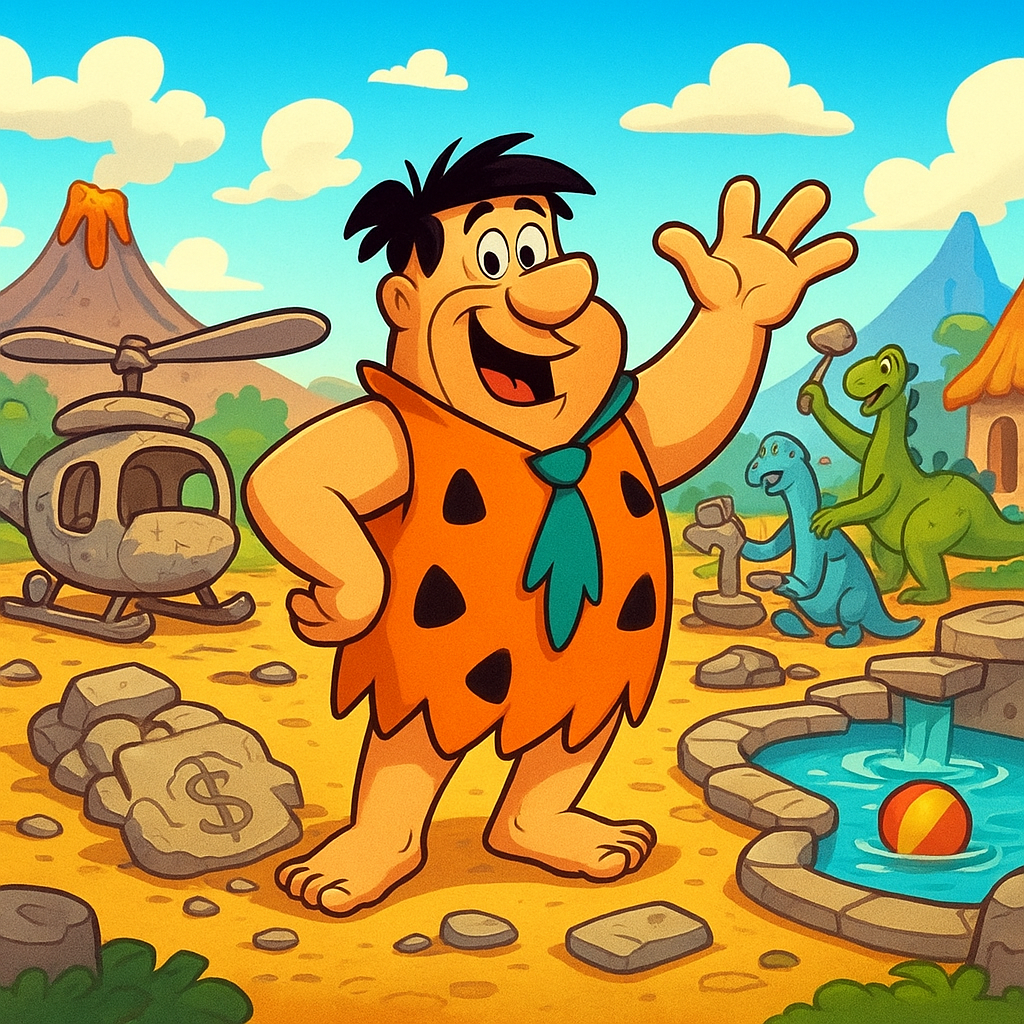


--- Article Output (Markdown) ---





Selected Research Brief:

Overview:
- Fred Flintstone is the main protagonist of the animated sitcom “The Flintstones” (ABC, 1960–1966). He’s a working-class caveman living in Bedrock with his wife Wilma and daughter Pebbles. Known for his catchphrase “Yabba-Dabba-Doo!”, Fred works as a crane operator and is characterized by a strong yet impulsive, short-tempered, and well-meaning personality.

Key Themes of Misadventures:
- Family vs. Work: Fred’s attempts to balance home life and his job often lead to comedic conflict (e.g., mishaps at work affecting his family).
- Pride and Showing Off: Many episodes revolve around Fred trying to prove himself or win prizes, only to end in slapstick disaster.
- Misunderstandings and Lies: Deceptions—well-intentioned or not—spur plots that unravel into chaotic, humorous scenarios.
- Friendship Dynamics: His relationship with best friend Barney Rubble is central, with Barney often dragged into Fred’s schemes.

Notable Episodes:
1. “The Little White Lie” (S1E28)
   - Fred misplaces money, leading Wilma to suspect theft. The ensuing confusion and frantic search provide the episode’s humor and tension.
2. “The Flintstone Flyer” (S1E16)
   - Barney builds a primitive helicopter which Fred renames. Their decision to fly to a bowling alley instead of an opera sparks airborne hijinks.
3. “No Help Wanted” (S2E2)
   - After Fred pushes his boss for a raise, Barney loses his job. Fred then bungles attempts to help Barney find new work, resulting in repossession antics.
4. “The Swimming Pool” (Pilot)
   - Fred and Barney’s joint pool project turns into a boundary dispute, culminates in a surprise birthday party, and highlights their friendship resilience.

Statistics:
- Original series: 166 episodes over 6 seasons (1960–1966).
- Seasons typically ranged from 26 to 32 episodes.
- Roughly 30–40% of episodes feature a major Fred-centric mishap driving the plot.

Sources:
1. https://en.wikipedia.org/wiki/List_of_The_Flintstones_episodes  
2. https://en.wikipedia.org/wiki/Fred_Flintstone  
3. https://episode.ninja/series/the-flintstones  
4. https://www.imdb.com/title/tt0580265

In [57]:
# Orchestrator run cell — set `topic` and run to produce article + image
# Edit the `topic` variable below to run a different topic. If left empty, a default will be used.
topic = "Fred Flinstone misadventures"  # <-- replace this text with your topic

from agents import trace
import base64
from IPython.display import Markdown, HTML, display

print('Running orchestrator for topic:', topic)
with trace("Article Writer Run", group_id="ManualRun"):
    result = await Runner.run(orchestrator_agent, input=topic, max_turns=40)

print('Last agent:', getattr(getattr(result, 'last_agent', None), 'name', 'N/A'))

# Embed local hero_image.png if present (image_agent saves this file)
img_html = None
try:
    with open('hero_image.png', 'rb') as f:
        img_b64 = base64.b64encode(f.read()).decode('utf-8')
        img_html = f'<img src="data:image/png;base64,{img_b64}" alt="Hero Image" width="800"/>'
except Exception as e:
    print('No local hero_image.png found or failed to read it:', e)

# Clean and display the orchestrator output, embedding the image above the markdown
clean_output = getattr(result, 'final_output', str(result))
clean_output = clean_output.replace('sandbox:/', '')

if img_html:
    # remove markdown image reference if present
    clean_output = clean_output.replace('![hero image](hero_image.png)', '')
    display(HTML(img_html))

print('\n--- Article Output (Markdown) ---\n')
display(Markdown(clean_output))


In [58]:
# Diagnostics for name/Agent/result issues
import inspect, sys
print("Python executable:", sys.executable)
print("Agent defined?", 'Agent' in globals())
print("choose_writer defined?", 'choose_writer' in globals())
print("result defined?", 'result' in globals())
if 'Agent' in globals():
    print("Agent object:", inspect.signature(Agent))
else:
    print("Agent not found; ensure the import cell ran.")

Python executable: /Users/hectoraltamira/AI-Engineering/AI Engineering Part 2/ai_env/bin/python
Agent defined? True
choose_writer defined? True
result defined? True
Agent object: (name: 'str', handoff_description: 'str | None' = None, tools: 'list[Tool]' = <factory>, mcp_servers: 'list[MCPServer]' = <factory>, mcp_config: 'MCPConfig' = <factory>, instructions: 'str | Callable[[RunContextWrapper[TContext], Agent[TContext]], MaybeAwaitable[str]] | None' = None, prompt: 'Prompt | DynamicPromptFunction | None' = None, handoffs: 'list[Agent[Any] | Handoff[TContext, Any]]' = <factory>, model: 'str | Model | None' = None, model_settings: 'ModelSettings' = <factory>, input_guardrails: 'list[InputGuardrail[TContext]]' = <factory>, output_guardrails: 'list[OutputGuardrail[TContext]]' = <factory>, output_type: 'type[Any] | AgentOutputSchemaBase | None' = None, hooks: 'AgentHooks[TContext] | None' = None, tool_use_behavior: "Literal['run_llm_again', 'stop_on_first_tool'] | StopAtTools | ToolsToFin